<a id="top"></a>
# House Sales: preparazione dati e primo modello di regressione (esercitazione)

Nel modulo 1 hai usato il dataset House Sales per inquadrare il problema: stimare il **prezzo di vendita** delle case in una certa area.  
Nel modulo 2, con il caso Bank Marketing, hai lavorato sulla preparazione di un dataset per un problema di **classificazione binaria**.

Qui resti nel contesto naturale di House Sales: **regressione sul prezzo**.  
L’obiettivo è replicare in versione compatta la pipeline di preparazione dati vista nel marketing bancario e collegarla a un primo modello lineare.

<a id="obiettivo-esercitazione"></a>
## Obiettivo dell'esercitazione

Nel caso Bank Marketing ti sei concentrato su una **classificazione**: prevedere se un cliente sottoscrive o meno un deposito (output binario 0/1).  
Nel caso House Sales torni al problema di **regressione**: il modello prevede un **numero continuo** (il prezzo), non una classe.

Riassumendo in due righe la differenza:

- **Classificazione**: l’output è una categoria (es. _sì/no_, _classe A/B/C_).  
- **Regressione**: l’output è un valore continuo (es. prezzo in euro).

In questa esercitazione:

- preparerai le feature in modo coerente con quanto fatto sul marketing (imputazione + normalizzazione robusta);
- allenerai un modello lineare (`LinearRegression`) per prevedere il prezzo;



<a id="caricamento-dataset"></a>
## Caricamento del dataset House Sales

Userai lo stesso dataset del notebook House Sales del modulo 1.  
Il dataset è su OpenML (id 42092) e si può scaricare con `fetch_openml` di scikit-learn.

- `fetch_openml` scarica un dataset da OpenML e restituisce un oggetto da cui puoi ricavare un DataFrame.  
  Documentazione: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_openml.html

Nel blocco seguente carichi i dati in un DataFrame `house` e dai un’occhiata alle prime righe.


In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

# Scarica il dataset House Sales da OpenML
raw = fetch_openml(data_id=42092, as_frame=True)  # House sales
house = raw.frame.copy()

print("Dimensioni del dataset (righe, colonne):", house.shape)
house.head()


Dimensioni del dataset (righe, colonne): (21613, 20)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


# Step 1: Preparazione del dato

Nel primo step dovrai preparare il dato:
1. separare X e y 
2. rimuovere le features inutilizzabili (date, zipcode, lat, long, yr_built, yr_renovated)
3. train test split (30% di test)


<div style="background-color:#f5f5f5; padding:10px; border-left:4px solid #999;">

**Attenzione**

In questo contesto ci accontentiamo di usare le variabili così come sono per faciilitare le prossime fasi. Ma la pratica del *feature engineering* prevede l'elaborazione di nuove variabili più utiili:
- yr_built -> età 
- yr_nenovated -> renovated?
- sqft_above, sqft_basement-> metri quadri totali  

</div>

In [2]:
from sklearn import set_config
from sklearn.model_selection import train_test_split
set_config(transform_output="pandas")


# rimuovere le colonne che non utilizzerò nel modello
colonne_da_rimuovere = [
    "date",
    "zipcode",
    "lat",
    "long",
    "yr_built",
    "yr_renovated"
]

# Separazione tra feature (X) e target (y)
X = house.drop(columns=["price", *colonne_da_rimuovere])
y = house["price"]

# Suddivisione: 70% training, 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Dimensioni di X_train:", X_train.shape)
print("Dimensioni di X_test:", X_test.shape)

#queste sono vuote, non ancora y fitted
print("Dimensioni di y_train:", y_train.shape)
print("Dimensioni di y_test:", y_test.shape)

Dimensioni di X_train: (15129, 13)
Dimensioni di X_test: (6484, 13)
Dimensioni di y_train: (15129,)
Dimensioni di y_test: (6484,)


## Step 2 : Pipeline di preprocessing 

Dovrai creare una pipeline di scikit composta da `SimpleImputer` e `RobustScaler`. In questo caso **non** ti servirà usare `ColumnTrasformer` perché tutte le features sono numeriche (verifica). 

Usa la mediana per l'imputazione di tutte le features:
- ("imputer", SimpleImputer(strategy="median"))
- https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# Verifica che tutte le feature siano numeriche
colonne_non_numeriche = X_train.select_dtypes(exclude="number").columns.tolist()
print("Colonne non numeriche:", colonne_non_numeriche)

# Pipeline di preprocessing
preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Adatta sul training set e trasforma entrambi i set
X_train_preprocessed = preprocessing.fit_transform(X_train)
X_test_preprocessed = preprocessing.transform(X_test)

print("Dimensioni X_train preprocessato:", X_train_preprocessed.shape)
print("Dimensioni X_test preprocessato:", X_test_preprocessed.shape)

Colonne non numeriche: []
Dimensioni X_train preprocessato: (15129, 13)
Dimensioni X_test preprocessato: (6484, 13)


## Step 3: Aggiungi anche `LinearRegression` come estimator in fondo alla pipeline. Produci delle previsioni sul test

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression

modello = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("regression", LinearRegression())
])

# Addestramento
modello.fit(X_train, y_train)

# Previsioni sul test set
y_pred = modello.predict(X_test)

print(y_pred[:10])

[ 553966.33266221  752322.13729963 1251867.86602962 1519499.43796542
  728043.44270647  340115.03265771  767415.64039654  499176.76316144
  445794.67807932  323528.86690404]


## Extra: se hai concluso puoi provare ad esplorare:

1. cambia strategia di imputing (mean invece di median)
2. cambia modello, from sklearn.ensemble import GradientBoostingRegressor (info: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html#sklearn.ensemble.GradientBoostingRegressor)

Molto avanzato: 
1. Fai uno stacking dei due modelli che hai allenato (https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingRegressor.html)


Matplotlib is building the font cache; this may take a moment.
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RidgeCV was fitted without feature names
  warnings.warn(


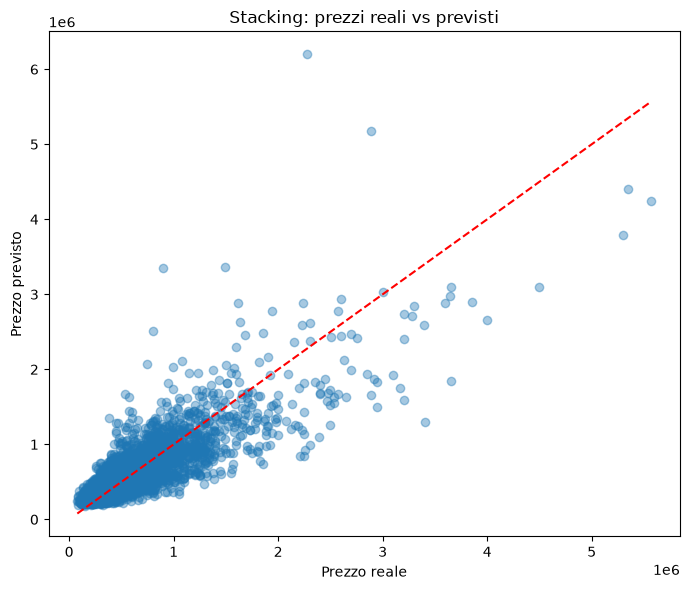

In [13]:
import matplotlib.pyplot as plt

y_pred_test = stacking.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_test, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Prezzo reale")
plt.ylabel("Prezzo previsto")
plt.title("Stacking: prezzi reali vs previsti")
plt.tight_layout()
plt.show()

c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazione\CORSO_IA_DATA_ANALYSIS\ai_course_data_analysis\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\a.ferri\OneDrive - UBroker SpA\Desktop\Ale\corso di formazi

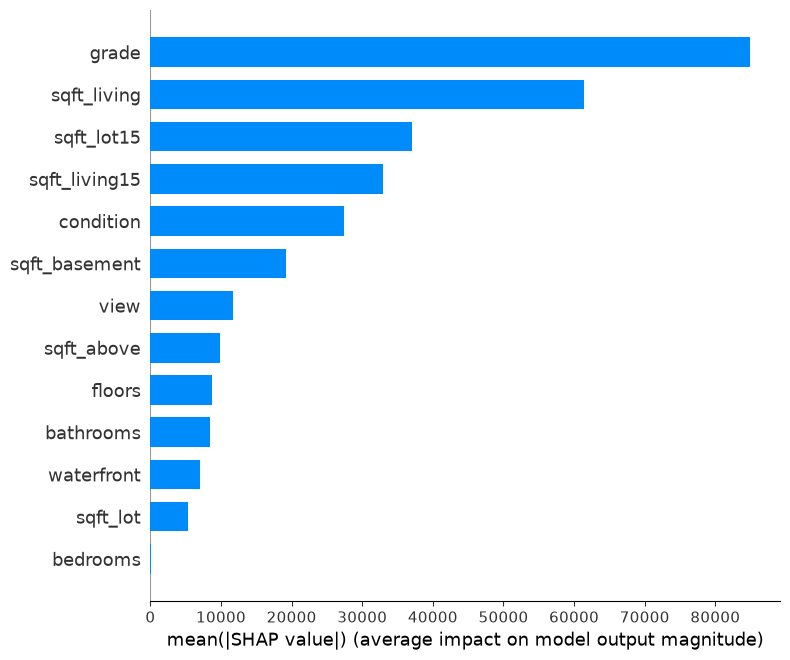

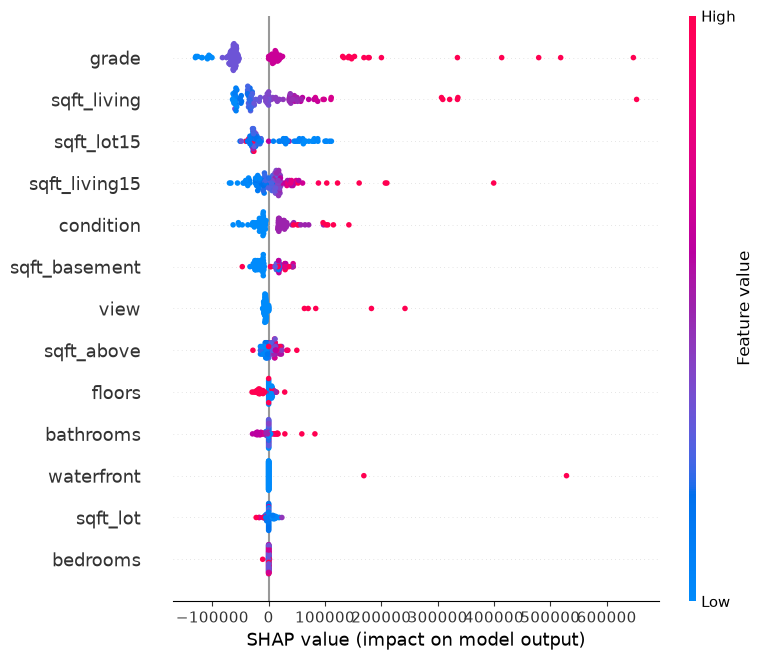

In [14]:
import shap

# Campioni ridotti per contenere i tempi di calcolo
background = shap.sample(X_train, 50, random_state=42)
X_shap = shap.sample(X_test, 100, random_state=42)

# Spiega le previsioni dello stacking nel loro complesso
explainer = shap.KernelExplainer(stacking.predict, background)
shap_values = explainer.shap_values(X_shap, nsamples=200)

# Importanza globale: media del contributo assoluto di ogni feature
shap.summary_plot(shap_values, X_shap, plot_type="bar")

# Distribuzione e direzione dei contributi sulle singole previsioni
shap.summary_plot(shap_values, X_shap)

In [ ]:
house